C:\Users\LJC\AppData\Local\Temp\ipykernel_295728\1695910222.py:7: DtypeWarning: Columns (0: NAME) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('ibtracs.ALL.list.v04r00.csv',


3.1 前10强飓风：
                   NAME  MAX_WIND
SID                              
2015293N13266  PATRICIA     185.0
1980214N11330     ALLEN     165.0
1935241N23291       NaN     160.0
1988253N12306   GILBERT     160.0
1997253N12255     LINDA     160.0
2005289N18282     WILMA     160.0
2019236N10314    DORIAN     160.0
1998295N12284     MITCH     155.0
2005261N21290      RITA     155.0
2009288N07267      RICK     155.0

3.2 前20最强风速值：
[185. 165. 160. 160. 160. 160. 160. 155. 155. 155. 155. 150. 150. 150.
 150. 150. 150. 150. 150. 150.]

3.3 各海盆数据点数量：
BASIN
WP    236576
SI    160668
SP     67119
EP     62412
NI     55402
SA       119
Name: count, dtype: int64


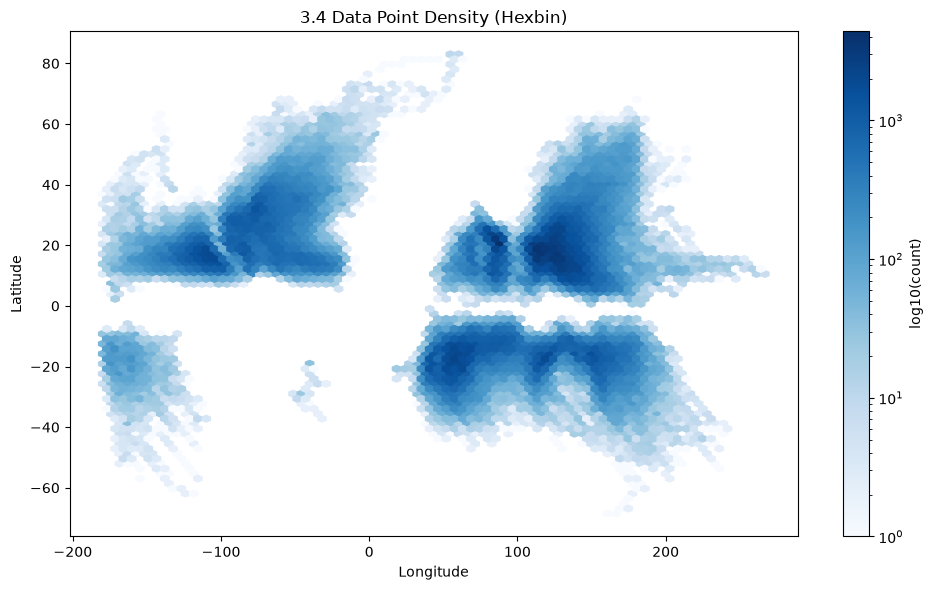

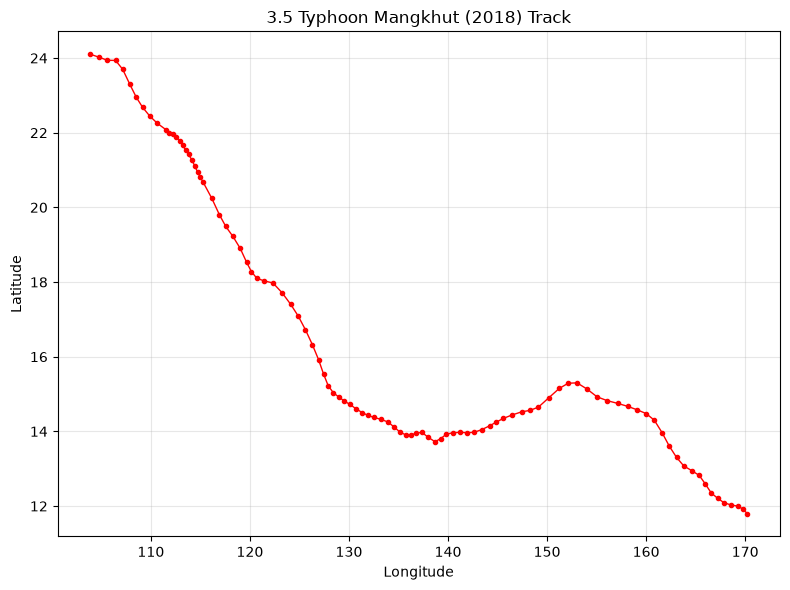


3.6 筛选后数据量：176352


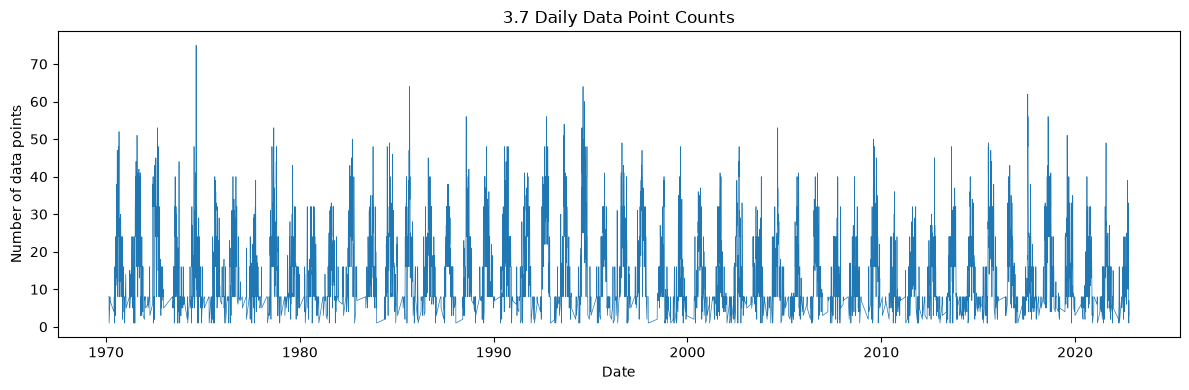

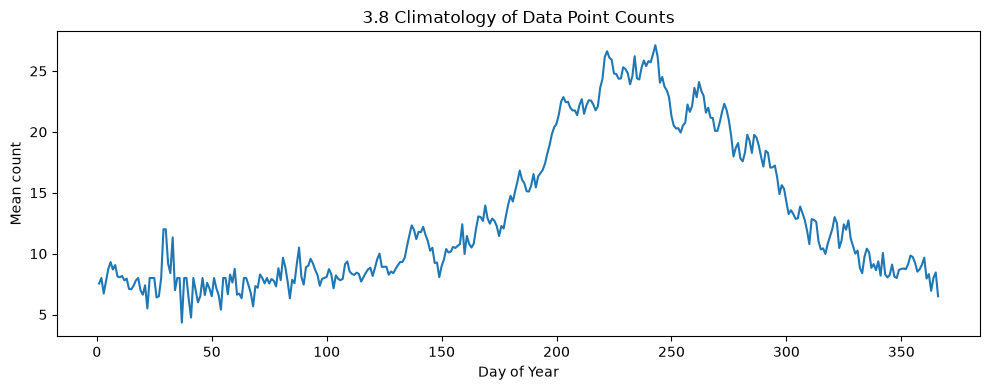

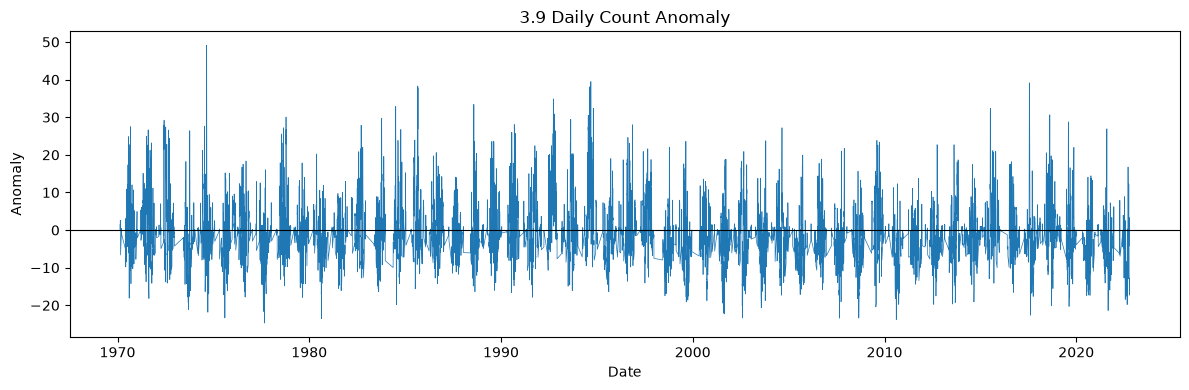

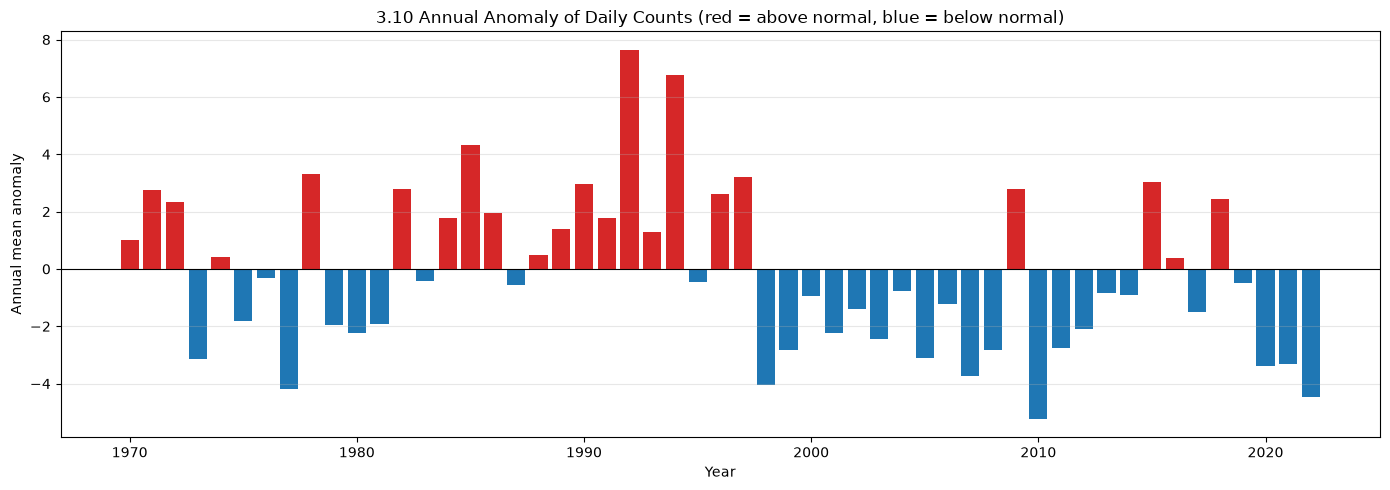


3.10 异常最显著的年份（按绝对值）：
ISO_TIME
1992-12-31    7.645086
1994-12-31    6.769985
2010-12-31    5.217217
2022-12-31    4.456293
1985-12-31    4.338109
1977-12-31    4.192921
1998-12-31    4.035779
2007-12-31    3.731739
2020-12-31    3.394267
2021-12-31    3.304806
dtype: float64


In [13]:
#导入
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#把字符串 'NOT_NAMED' 和 'NAME' 当作缺失值（NaN）处理
df = pd.read_csv('ibtracs.ALL.list.v04r00.csv',
                 usecols=range(17),
                 skiprows=[1],
                 parse_dates=['ISO_TIME'],
                 na_values=['NOT_NAMED', 'NAME'])

#把这三列强制转为数值型，将无法转换的值（空字符串、空格等）变成 NaN 
for col in ['WMO_WIND', 'LAT', 'LON']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    
#3.1取 WMO_WIND 的最大值，删除 MAX_WIND 为 NaN 的风暴，按 MAX_WIND 降序取前 10 名
storm_max = df.groupby('SID').agg(
    NAME=('NAME', 'first'),
    MAX_WIND=('WMO_WIND', 'max')
).dropna(subset=['MAX_WIND'])

top10 = storm_max.nlargest(10, 'MAX_WIND')
print("3.1 前10强飓风：")
print(top10[['NAME', 'MAX_WIND']])

#3.2从每个风暴的最大风速中取前 20 个值
top20_winds = storm_max['MAX_WIND'].nlargest(20).values
print("\n3.2 前20最强风速值：")
print(top20_winds)

#3.3统计 BASIN 列每个海盆（WP、EP、NA、SI 等）出现的记录数
basin_counts = df['BASIN'].value_counts()
print("\n3.3 各海盆数据点数量：")
print(basin_counts)

#3.4画图
fig, ax = plt.subplots(figsize=(10, 6))
hb = ax.hexbin(df['LON'], df['LAT'],
               gridsize=80, cmap='Blues', bins='log', mincnt=1)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('3.4 Data Point Density (Hexbin)')
plt.colorbar(hb, ax=ax, label='log10(count)')
plt.tight_layout()
plt.savefig('3_4_hexbin.png', dpi=100)
plt.show()

#3.5筛选出名字为 MANGKHUT 的所有记录，再筛选 2018 年的那条，并按时间排序
mangkhut = df[df['NAME'] == 'MANGKHUT']
mangkhut_2018 = mangkhut[mangkhut['ISO_TIME'].dt.year == 2018].sort_values('ISO_TIME')

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(mangkhut_2018['LON'], mangkhut_2018['LAT'],
        marker='o', markersize=3, linewidth=1, color='red')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('3.5 Typhoon Mangkhut (2018) Track')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('3_5_mangkhut.png', dpi=100)
plt.show()

#3.6保留两个条件同时满足的行：年份 ≥ 1970，且海盆是 WP或EP
df_filt = df[(df['ISO_TIME'].dt.year >= 1970) &
             (df['BASIN'].isin(['WP', 'EP']))].copy()
print(f"\n3.6 筛选后数据量：{len(df_filt)}")

daily_counts = df_filt.set_index('ISO_TIME').resample('D').size()
daily_counts = daily_counts[daily_counts > 0]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily_counts.index, daily_counts.values, linewidth=0.5)
ax.set_xlabel('Date')
ax.set_ylabel('Number of data points')
ax.set_title('3.7 Daily Data Point Counts')
plt.tight_layout()
plt.savefig('3_7_daily_counts.png', dpi=100)
plt.show()

#3.8提取每个日期是一年中的第几天（1~366），按 day-of-year 分组，对多年同一天的数据取平均，得到气候态，把索引补齐为 1~366，interpolate() 线性插值填补缺失值
doy = daily_counts.index.dayofyear
clim = daily_counts.groupby(doy).mean()
clim = clim.reindex(range(1, 367)).interpolate()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(clim.index, clim.values)
ax.set_xlabel('Day of Year')
ax.set_ylabel('Mean count')
ax.set_title('3.8 Climatology of Data Point Counts')
plt.tight_layout()
plt.savefig('3_8_climatology.png', dpi=100)
plt.show()

#3.9
clim_aligned = clim.reindex(daily_counts.index.dayofyear).values
#用每日实际计数减去对应日期的气候态，得到异常值
anomaly = pd.Series(daily_counts.values - clim_aligned,
                    index=daily_counts.index)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(anomaly.index, anomaly.values, linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Date')
ax.set_ylabel('Anomaly')
ax.set_title('3.9 Daily Count Anomaly')
plt.tight_layout()
plt.savefig('3_9_anomaly.png', dpi=100)
plt.show()

#3.10
#新版本 pandas（≥2.2）用 'YE'（year end），旧版本用 'A'，try/except 让代码在两种版本下都能运行
try:
    annual_anomaly = anomaly.resample('YE').mean()
except ValueError:
    annual_anomaly = anomaly.resample('A').mean()

fig, ax = plt.subplots(figsize=(14, 5))

years = annual_anomaly.index.year
values = annual_anomaly.values
colors = ['#d62728' if v > 0 else '#1f77b4' for v in values]

ax.bar(years, values, width=0.8, color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Year')
ax.set_ylabel('Annual mean anomaly')
ax.set_title('3.10 Annual Anomaly of Daily Counts (red = above normal, blue = below normal)')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('3_10_annual_anomaly.png', dpi=100)
plt.show()
#先取每年异常的绝对值 .abs()（偏多偏少都算"异常大"），再 .nlargest(10) 取最大的 10 个，得到异常最显著的 10 个年份
top_years = annual_anomaly.abs().nlargest(10)
print("\n3.10 异常最显著的年份（按绝对值）：")
print(top_years)